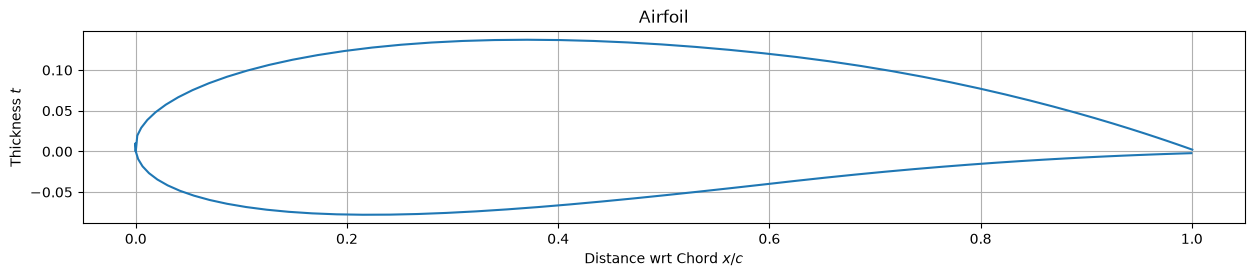

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Airfoil Plotting
a = 51    ## Number of points for plotting 
beta = np.linspace(0, np.pi, a)
x = 0.5 * (1 - np.cos(beta))

m = np.random.randint(2, 5) / 100       # Maximum Camber
p = np.random.randint(2, 8) / 10        # Location of Maximum Camber
t = np.random.randint(10, 25) / 100     # Maximum Thickness

#Initiate arrays
y_t = np.zeros(len(x))
y_c = np.zeros(len(x))
dyc_dx = np.zeros(len(x))
theta = np.zeros(len(x))
x_u = np.zeros(len(x))
x_l = np.zeros(len(x))
y_u = np.zeros(len(x))
y_l = np.zeros(len(x))
y_reconstructed_u = np.zeros(len(x))
y_reconstructed_l = np.zeros(len(x))
y_reconstructed_u_1 = np.zeros(len(x))
y_reconstructed_l_1 = np.zeros(len(x))

#Original Airfoil Generation 
for i in range(len(x)):
    y_t[i] = 5*t*(0.2969*(x[i]**0.5)        # Thickness distribution
               - 0.1260*x[i]
               - 0.3516*(x[i]**2)
               + 0.2843*(x[i]**3)
               - 0.1015*(x[i]**4))

    if 0 <= x[i] <= p:                      # Camber line and slope
        y_c[i] = (m / p**2) * (2*p*x[i] - x[i]**2)
        dyc_dx[i] = (2*m / p**2) * (p - x[i])

    elif p < x[i] <= 1:
        y_c[i] = (m / (1-p)**2) * ((1 - 2*p) + 2*p*x[i] - x[i]**2)
        dyc_dx[i] = (2*m / (1-p)**2) * (p - x[i])
        
    theta[i] = np.arctan(dyc_dx[i])         # Angle of camber line
    
    x_u[i] = x[i] - y_t[i]*np.sin(theta[i]) # Upper and lower surfaces
    x_l[i] = x[i] + y_t[i]*np.sin(theta[i])
    y_u[i] = y_c[i] + y_t[i]*np.cos(theta[i])
    y_l[i] = y_c[i] - y_t[i]*np.cos(theta[i])

idx_u = np.argsort(x_u)
idx_l = np.argsort(x_l)

x_u, y_u = x_u[idx_u], y_u[idx_u]
x_l, y_l = x_l[idx_l], y_l[idx_l]

# Combine upper and lower surfaces
x_full = np.concatenate((x_u[::-1], x_l))
y_full = np.concatenate((y_u[::-1], y_l))

plt.figure(figsize=(15, 2.5))
plt.plot(x_full, y_full)
plt.xlabel("Distance wrt Chord $x/c$")
plt.ylabel("Thickness $t$")
plt.title("Airfoil")
plt.grid(True)
plt.show()
